# Эксперименты с признаками и результаты прогона: что получилось и как это читать

Ноутбук ничего не обучает: он показывает и объясняет уже полученные результаты.

1. **Эксперименты с признаками** — что пробовали, чтобы улучшить модель, и что из этого вышло.
2. **Прогон `run_all.py`** от 11.10.2026: пять моделей (четыре из статьи и CatBoost), все метрики статьи,
   новые метрики и важность признаков по Шепли. Полные таблицы — в [RESULTS.md](RESULTS.md).
3. **Короткие выводы** для плаката.

Картинки — скриншоты из отчёта (папка `screenshots/`). Как читать графики Шепли и SHAP подробно, с подписанными
примерами, — в [docs/SHAPLEY_RU.md](../../docs/SHAPLEY_RU.md).

## 1. Эксперименты с признаками

**Что сравнивали.** Одна и та же постановка задачи (сон против бодрствования), меняли только признаки, веса
классов или порог. Две метрики:

* **κ (каппа Коэна)** — насколько метки модели совпадают с PSG сверх случайного совпадения. Зависит от порога.
* **ROC AUC** — насколько хорошо модель **упорядочивает** эпохи от «точно бодрствование» до «точно сон». Не
  зависит от порога.

> Постановка эксперимента: нейросеть MLP (15, 15, 15), базовые признаки motion, hr и **cosine** (а не clock),
> порог P(сон) ≥ 0.5. Поэтому исходные 3 признака здесь дают κ 0.496 и AUC 0.908, а в таблицах статьи ниже
> (motion, hr, clock; порог «сон найден = 0.9») — κ около 0.43 и AUC около 0.88. Эксперименты сравниваем
> **между собой**. Формулы быстрых признаков — в `repro/fast_features.py`; то же сравнение для CatBoost и
> нейросети в общей постановке проекта — `python repro/10_fast_features.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

exp = pd.read_csv("feature_experiments.csv")
base = exp.iloc[0]
exp["Δκ"] = (exp.kappa - base.kappa).round(3)
exp["ΔAUC"] = (exp.roc_auc - base.roc_auc).round(3)
pd.set_option("display.max_colwidth", 90)
exp[["experiment", "description", "kappa", "Δκ", "roc_auc", "ΔAUC"]]

,experiment,description,kappa,Δκ,roc_auc,ΔAUC
0,Исходные 3 признака,"motion, hr, clock — как в статье (точка отсчёта)",0.496,0.000,0.908,0.000
1,Соседние эпохи,к признакам эпохи добавлены значения соседних эпох,0.519,0.023,0.912,0.004
2,Изменения относительно соседних эпох,"признаки быстрого изменения активности и пульса относительно соседних эпох, без сглажи...",0.494,-0.002,0.907,-0.001
3,Статистики короткого окна,среднее и стандартное отклонение активности и пульса в небольшом окне,0.508,0.012,0.909,0.001
4,Статистики + изменения,"и статистики окна, и признаки изменений",0.503,0.007,0.911,0.003
5,Разное в статистиках,на обучающих данных выбирали между вариантами статистик окна и их сочетаниями с измене...,0.512,0.016,0.910,0.002
6,Больше веса бодрствованию,"примеры бодрствования повторялись в обучающей выборке, чтобы модель уделяла им больше ...",0.491,-0.005,0.903,-0.005
7,Изменение порога,порог 0.5 заменён на подобранный по участникам,0.492,-0.004,0.908,0.000
8,Окно + порог,выбранное окно статистик + подобранный порог,0.523,0.027,0.912,0.004
9,Исходные + 3 быстрых признака,"исходные признаки + пик движения, доля активных отрезков за минуту и относительный пул...",0.534,0.038,0.917,0.009


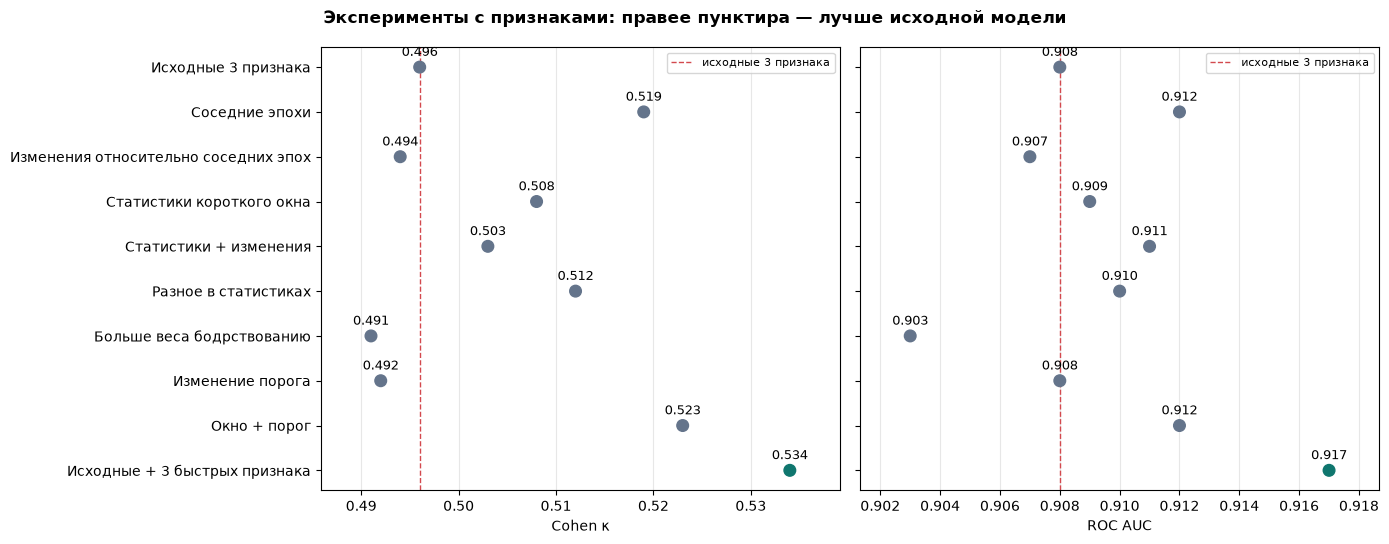

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
y = range(len(exp))[::-1]
best = exp.kappa.idxmax()
for ax, col, label in [(axes[0], "kappa", "Cohen κ"), (axes[1], "roc_auc", "ROC AUC")]:
    colors = ["#0f766e" if i == best else "#64748b" for i in exp.index]
    ax.scatter(exp[col], y, color=colors, s=70, zorder=3)
    ax.axvline(base[col], color="#d3494e", ls="--", lw=1, label="исходные 3 признака")
    for yi, v in zip(y, exp[col]):
        ax.text(v, yi + 0.25, f"{v:.3f}", ha="center", fontsize=9)
    ax.set_xlabel(label)
    ax.grid(axis="x", alpha=.3)
    ax.margins(x=0.12)
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_yticks(list(y), exp.experiment)
fig.suptitle("Эксперименты с признаками: правее пунктира — лучше исходной модели", fontweight="bold")
fig.tight_layout()

### Что видно

* **Лучший вариант — «исходные + 3 быстрых признака»** (пик движения, доля активных отрезков за минуту,
  относительный пульс за минуту): κ 0.534 (+0.038) и AUC 0.917 (+0.009). Это единственный вариант, который
  заметно улучшил **обе** метрики. Быстрые признаки ловят короткие пробуждения, которые сглаженный motion
  «размазывает».
* **Соседние эпохи помогают** (κ +0.023). Сон «липкий»: если соседние эпохи — сон, то и эта, скорее всего, сон.
  Контекст нескольких минут даёт модели то, чего нет в одной эпохе.
* **Окно + порог** (κ 0.523) лучше, чем окно (0.508–0.512) или порог (0.492) по отдельности.
* **Изменения без сглаживания** (κ 0.494, AUC 0.907) **не помогли**: разности соседних эпох очень шумные, и
  модель не может отличить настоящую смену состояния от шума датчика.
* **Больше веса бодрствованию — хуже всего** (κ 0.491, AUC 0.903). Повторение примеров бодрствования сдвигает
  вероятности в сторону wake и приучает модель к одним и тем же редким примерам (переобучение). AUC при этом
  тоже упал: стал хуже сам порядок эпох, а не только порог.
* **Изменение порога не меняет AUC** (0.908 = 0.908), и это правильно: AUC не зависит от порога. По κ порог,
  подобранный по участникам, сам по себе не помог (0.492): на новых людях он ведёт себя иначе, чем на обучающих.

**Насколько это надёжно.** Различия маленькие: по AUC меньше 0.01, по κ до 0.04. Людей всего 31, поэтому перед
выводом «вариант лучше» стоит посчитать доверительные интервалы бутстрепом по людям. Самый устойчивый кандидат —
«исходные + 3 быстрых признака»: он лучший по обеим метрикам сразу.

Исходный график команды:

![эксперименты с признаками: κ и AUC](screenshots/feature_experiments.png)

## 2. Прогон `run_all.py`: пять моделей

Протокол для всего раздела: **leave-one-subject-out** — каждый человек предсказывается моделью, которая его не
видела. Четыре модели статьи (логистическая регрессия, k ближайших соседей, случайный лес, нейросеть) и CatBoost.
Признаки — как в статье: Motion only, HR only, Motion + HR, Motion + HR + Clock.

### Главные числа (Motion, HR, Clock; порог «сон найден» = 0.9)

| модель | accuracy | AUC | AUC статья | wake найден | κ | AP wake | F1 wake | macro F1 |
|---|---|---|---|---|---|---|---|---|
| Логистическая регрессия | 0.876 | 0.860 | 0.854 | 0.617 | 0.392 | 0.479 | 0.457 | 0.693 |
| k ближайших соседей | 0.880 | 0.867 | 0.868 | 0.668 | 0.424 | 0.502 | 0.486 | 0.709 |
| Случайный лес | 0.880 | 0.869 | 0.871 | 0.660 | 0.418 | 0.562 | 0.481 | 0.707 |
| Нейросеть (MLP) | 0.881 | 0.877 | 0.878 | 0.677 | 0.429 | 0.560 | 0.491 | 0.712 |
| **CatBoost** | **0.881** | **0.880** | — | **0.680** | **0.431** | 0.547 | **0.492** | **0.713** |

* AUC совпадает со статьёй в пределах 0.01: воспроизведение удалось.
* **CatBoost — лучший по большинству метрик**, но отрыв от нейросети статьи в тысячных. Задача упирается в
  признаки, а не в модель.
* **Accuracy почти одинаковая (0.876–0.881)** и мало что говорит: модель «всегда сон» уже даёт 0.916. Разницу
  видно по wake найден, κ и F1 wake.

### Сводка: AUC, κ и F1 wake

![все модели и наборы признаков](screenshots/fig_summary_models.png)

* Цвет — набор признаков, группа — модель. **Красный (Motion + HR + Clock) лучший у всех моделей.**
* **Оранжевый (только HR) — худший**: по одному пульсу бодрствование почти не видно (κ 0.13–0.18).
* Motion + HR (зелёный) почти не лучше одного Motion (синий) по κ и F1: пульс мало добавляет к движению.
  А clock добавляет заметно: κ растёт с 0.32–0.35 до 0.39–0.43.

### Рис. 2: ROC сон/бодрствование

![ROC](screenshots/fig2_roc_sleep_wake.png)

* По оси x — доля бодрствования, ошибочно названная сном, по оси y — доля найденного сна. Чем ближе кривая к
  левому верхнему углу, тем лучше. Пунктир — случайная модель.
* **Прямые отрезки у Motion only** (синяя линия, особенно у k ближайших соседей и случайного леса в начале).
  У половины эпох motion ровно 0, модель даёт им одинаковую вероятность. Когда порог проходит через эту группу,
  сразу много эпох меняют метку, и кривая идёт прямой линией. Это «ничьи» в данных, а не ошибка.
* Красная кривая (все признаки) выше всех у каждой модели; оранжевая (HR) — ниже всех.

### Рис. 3: precision–recall для бодрствования

![precision-recall](screenshots/fig3_pr_wake.png)

* Бодрствование — редкий класс (8.4% эпох), поэтому эта картинка честнее ROC. По оси x — какая доля
  бодрствования найдена (recall), по оси y — какая доля из названных «бодрствованием» правда бодрствование
  (precision).
* **Пунктир внизу (0.084) — случайная модель**: её precision равна доле бодрствования.
* **AP (площадь) с clock — 0.48–0.56**, у случайного леса и нейросети выше всех. Только HR — 0.15–0.23, почти
  случайно.
* Кривые быстро падают: найти **больше половины** бодрствования можно, только если каждую вторую-третью
  тревогу делать ложной. Это главный предел этих признаков.

### Рис. 4: три класса (бодрствование / NREM / REM)

![три класса](screenshots/fig4_three_class.png)

* По оси x — доля бодрствования, ошибочно названная сном (NREM или REM), по оси y — средняя доля найденных NREM и
  REM (порог подобран так, чтобы они были поровну).
* Все кривые выходят на **плато около 0.68**: даже если почти не искать бодрствование, NREM и REM различаются
  только в двух случаях из трёх.
* **Синяя пунктирная и штриховая** — отдельно NREM и REM для Motion only. У k ближайших соседей они ломаются
  ступенькой: те же «ничьи» при motion = 0, из-за которых порог не может разделить группу.

### Новые метрики (в статье их нет)

![новые метрики](screenshots/fig_new_metrics.png)

* **AP wake** (слева вверху) — та же площадь под PR-кривой, что на рис. 3.
* **PPV wake ≈ 0.36–0.39** (справа вверху): из эпох, которые модель назвала бодрствованием при 90% найденного
  сна, правда бодрствованием оказывается примерно **каждая третья**.
* **Три класса: macro F1 ≈ 0.57–0.59, F1 REM ≈ 0.48–0.50** при уравненных NREM и REM. REM — самый трудный класс.

### F1 бодрствования в зависимости от порога

![F1 от порога](screenshots/fig_f1_threshold_models.png)

* Каждая кривая — F1 бодрствования при разных порогах на P(wake). Точка — лучший порог.
* **Лучший F1 почти одинаковый (0.47–0.54), но порог совсем разный: от 0.22 до 0.81.** Модели с весами классов
  (случайный лес 0.76, CatBoost 0.81) завышают P(wake), и им нужен высокий порог. Нейросеть (0.27) и k
  ближайших соседей (0.22) обучены без весов, их P(wake) занижены.
* Логистическая регрессия начинается только с 0.25: из-за сильной регуляризации (C = 0.001) её вероятности
  сжаты к середине и не бывают меньше 0.25.
* Вывод: **порог 0.5 «по умолчанию» для этих моделей не подходит**, его надо подбирать под модель. При этом
  подбирать его нужно на обучающих людях, а не на тестовых.

## 3. Важность признаков

### Шепли по качеству: модели переобучены на всех подмножествах признаков

![Шепли по AUC](screenshots/fig_shapley_auc.png)

* **Слева** — AUC каждой модели на всех 7 подмножествах {motion, hr, clock}. Один clock (Clock only) даёт
  0.61–0.68: время ночи само по себе кое-что говорит. **Motion + Clock (0.85–0.87) почти не хуже всех трёх**:
  пульс добавляет мало.
* **Справа** — значение Шепли: средний прирост AUC от признака по всем порядкам добавления. **Motion
  0.15–0.19, hr 0.09–0.11, clock 0.08–0.12.** Сумма трёх столбиков у модели = её AUC − 0.5.

![Шепли по шести метрикам](screenshots/fig_shapley_metrics.png)

* То же для шести метрик. В подписи — качество случайной модели, от которого считается вклад.
* По **accuracy** вклады крошечные (0.007–0.022): случайная модель уже даёт 0.832. Поэтому accuracy плохо
  подходит, чтобы сравнивать признаки.
* По **AP wake, κ и F1 wake clock почти догоняет motion**, а hr сильно отстаёт. Для поиска бодрствования время
  ночи важнее пульса.

![доли Шепли](screenshots/fig_shapley_share.png)

* Доли в процентах; в каждой строке внутри одной метрики сумма = 100%. Чем краснее, тем больше доля.
* **Motion — 42–57%, clock — 22–43%, hr — 9–30%** у всех моделей. Картина одинаковая для всех моделей: важность
  признаков — свойство данных, а не конкретной модели.
* Самая маленькая доля — **hr для AP wake (9–15%)**: пульс помогает упорядочить эпохи в целом, но почти не
  помогает точно находить бодрствование.

### SHAP: как модель использует признаки в каждой эпохе

![mean |SHAP|](screenshots/fig_shap_mean_abs.png)

* **Слева — mean |SHAP|**: насколько в среднем признак сдвигает P(сон) в одной эпохе. У случайного леса и
  CatBoost значения в 2–4 раза больше. Это масштаб вероятностей, а не важность: их вероятности разбросаны
  шире, а у логистической регрессии (сильная регуляризация) и нейросети (без весов классов) прижаты.
* **Справа — доли**, их и надо сравнивать: motion 45–57%, clock 29–39%, hr 13–23%.

![бисворм](screenshots/fig_shap_beeswarm_models.png)

* Точка — эпоха, ось x — на сколько признак сдвинул P(сон) (правее нуля — к сну), цвет — значение признака
  (синий — мало, красный — много), толщина роя — сколько эпох с таким сдвигом.
* **Motion у всех моделей:** синий ком справа (покой → сон) и длинный красный хвост влево (движение →
  бодрствование, до −0.6…−0.9).
* **Clock у логистической регрессии** — плавный переход цвета от синего к красному: модель линейная, поэтому
  вклад ровно растёт со значением. У деревьев (случайный лес, CatBoost) цвета перемешаны: вклад зависит ещё и от
  других признаков.
* **Hr у логистической регрессии, k ближайших соседей и нейросети почти не двигает предсказание** (узкий рой,
  |SHAP| около 0.02), у деревьев — заметно сильнее (около 0.065).

![SHAP dependence: логистическая регрессия, kNN, случайный лес](screenshots/fig_shap_dependence_models_part1.png)

![SHAP dependence: нейросеть, CatBoost](screenshots/fig_shap_dependence_models_part2.png)

* Ось x — значение признака, ось y — его вклад в P(сон), цвет — **другой** признак (подписан справа).
* **Логистическая регрессия — почти прямые линии** (hr и clock). Вклад линейной модели зависит только от
  значения признака. Несколько параллельных полос у clock — эпохи с разными motion: сигмоида по-разному
  переводит одинаковый сдвиг в вероятность.
* **Деревья (случайный лес, CatBoost) — ступеньки и провал около clock ≈ 0.8**: модель режет ось порогами и
  запоминает несколько ночей с пробуждениями в это время.
* **Нейросеть и k ближайших соседей — гладкие кривые**; у k ближайших соседей больше шума, потому что ответ —
  среднее по 500 похожим эпохам.
* У всех моделей одна и та же форма: **покой → сон, движение → бодрствование; начало ночи (clock около 0) →
  бодрствование; ровный пульс → немного к сну**.

## 4. Короткие выводы (для плаката)

1. **Воспроизведение удалось:** AUC моделей статьи совпал с опубликованным в пределах 0.01 (0.86–0.88).
2. **CatBoost немного лучше всех** (AUC 0.880, κ 0.431, F1 wake 0.492), но отрыв от нейросети статьи в тысячных:
   качество упирается в признаки, а не в модель.
3. **Главный признак — движение** (около половины вклада по Шепли), затем **время ночи (clock)**. **Пульс
   добавляет меньше всего**, особенно для поиска бодрствования.
4. **Главная трудность — бодрствование:** при 90% найденного сна модели находят около 2/3 бодрствования, и
   только каждая третья метка «бодрствование» верна (PPV 0.36–0.39). Тихое бодрствование без движения модели не
   видят.
5. **Accuracy обманчива:** «всегда сон» даёт 0.916, модели — 0.88. Сравнивать нужно по κ, F1 wake и AP.
6. **Порог надо подбирать под модель:** лучший порог на P(wake) — от 0.22 до 0.81.
7. **Новые признаки помогают:** «исходные + 3 быстрых признака» — κ 0.496 → 0.534, AUC 0.908 → 0.917. Соседние
   эпохи тоже помогают; повтор примеров бодрствования и признаки без сглаживания — нет.